In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pprint import pprint
import flups
import scistyles
import colorcet
#from spectro.utils import between, argnear
from glob import glob
import lmfit
from pyspan.utils import conv_exp
from flups.analysis import shift_trace
#from spectro.utils import nm2ev
from scipy.signal import savgol_filter
from scipy.ndimage import gaussian_filter
import pandas as pd
import sympy as sy
import seaborn as sns
import scipy.constants as const

In [2]:
%matplotlib widget

In [3]:
def between(x, l, u):
    return (x>l) & (x<u)

def nm2eV(nm):
    return const.h * const.c / (const.e * nm * 1e-9) 

# Load data

In [4]:
#when lambda allready calculated

data = {
    fn.split("_")[0]: (t, wl, s)
    for fn in ["run02.dat"]
    for t, wl, s in [flups.io.load_txt(fn)]
}

In [5]:
for fn, (t,wl,s) in data.items():
    print(fn)
    print(t.shape, wl.shape, s.shape)
    print(t[0],t[-1])
    print()

run02.dat
(251,) (1600,) (251, 1600)
-1.5 3.5



TypeError: 'Axes' object is not iterable

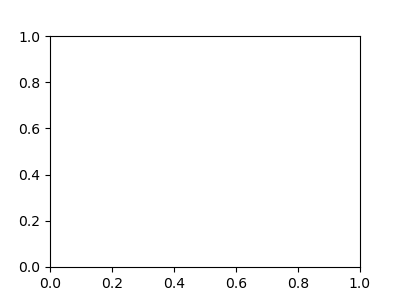

In [6]:
ncols = len(data)
fig, axes = plt.subplots(ncols=ncols, figsize=(4*ncols, 3), sharex=True, sharey=True)
vmin=-10
for ax, (fn, (t, wl, s)) in zip(axes, data.items()):
    plt.sca(ax)
    vmax = np.percentile(s, 99)
    plt.pcolormesh(t, wl, s.T, cmap="Blues", vmin=vmin, vmax=vmax, rasterized=True)
    plt.text(0.95, 0.95, fn, ha="right", va="top", transform=ax.transAxes)
    plt.colorbar(label="counts")
    plt.xlabel("t/ ps")
    plt.ylabel(r"$\lambda_U$ (nm)")

# Compute kinetics

In [24]:
bands = {}
wl_cc = 266 #273 #268
for sample in data:
    bands[sample, wl_cc] = 264, 266#(270, 276) #(264, 274)

    #(full signal should be 286, 314)
for lo in range(280, 340, 2):
    hi = lo + 2
    if not (hi > 327 and lo < 329):     
        bands["run02.dat", lo + 1] = (lo, hi)
        
#for lo in range(310, 366, 5):
#    hi = lo + 2.5
#    if not (hi > 344 and lo < 356):     
#        bands["PBBO", lo + 5] = (lo, hi)

#for lo in range(316, 366, 6):
    #bands["BBOT", lo+1] = (lo, lo+2)

kins = {}
for (sample, bnd), (lo, hi) in bands.items():
    t, wl, s = data[sample]
    kins[sample, bnd] = s.compress(between(wl, lo, hi), axis=1).mean(axis=1)

In [25]:
print(wl_cc)

266


# Fit CC

In [26]:
model_cc = lmfit.models.GaussianModel() + lmfit.models.ConstantModel()
guess = model_cc.make_params()
guess["amplitude"].set(value=1000, min=0)
guess["center"].set(value=1)
guess["sigma"].set(value=0.2, min=0.02)
guess

results_cc = {}
for fn, (t,wl,s) in data.items():
    b = (fn, wl_cc)
    k = kins[b]
    r = model_cc.fit(k, params=guess, x=t)
    print(f"{b} {r.message}")
    results_cc[b] = r

('run02.dat', 266) Fit succeeded.


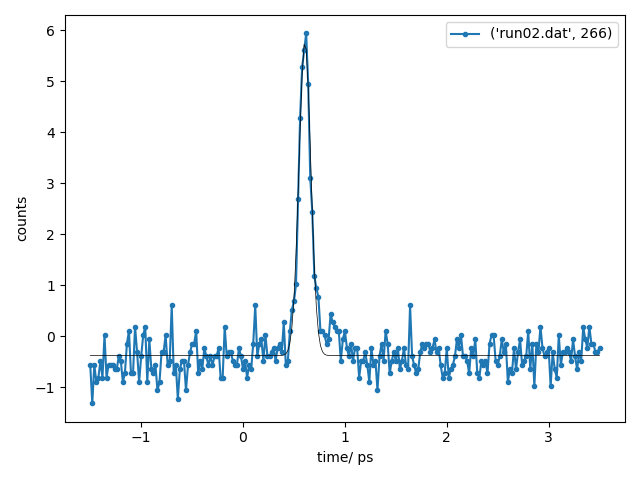

In [27]:
plt.figure()
for b, r in results_cc.items():
    fn, _ = b
    t = data[fn][0] 
    plt.plot(t, kins[b], '.-', label=b)
    plt.plot(t, r.best_fit, color="k", lw=0.5)
plt.legend()
plt.xlabel("time/ ps")
plt.ylabel("counts")
plt.tight_layout()
plt.show()

In [28]:
r.params["sigma"].value
r.params["sigma"].value, r.params["sigma"].stderr

(0.05814421339726117, 0.0019302726610881474)

In [29]:
for b, r in results_cc.items():
    sigma = r.params["sigma"].value
    fwhm = 2.355 * sigma
    print(b, fwhm)

('run02.dat', 266) 0.13692962255055005


In [30]:
print(wl)

[248.681 248.853 249.025 ... 521.99  522.16  522.329]


# Fit fluorescence kinetics

In [31]:
# first pass. `conv_exp` contains both the single exponential and the sigmoid.
model_sig = lmfit.Model(conv_exp) + lmfit.models.ConstantModel()
guesses = {}

guess = model_sig.make_params()
guess["amp"].set(value=100, vary=True)
guess["tau"].set(value=1, max=500, min=0.02, vary=True)
guess["sigma"].set(value=0.1, min=0.02)
guess["t0"].set(value=0.0) #0.5
guess["y0"].set(value=0, vary=True, min=0, max= 5000)
guess["c"].set(value=0, vary=False, min=-100, max=100)

guesses["run02.dat"] = guess.copy()
#guesses["BBOT"] = guess.copy()


results = {}
for b, k in kins.items():
    fn = b[0]
    t= data[fn][0]
    if b[1] == wl_cc: continue # is CC
    g = guesses[b[0]]
    y_ = np.mean(k[-10:])
    g["y0"].set(value=y_)
    g["c"].set(value=np.mean(k[:10]))
    m = np.isfinite(k)
    r = model_sig.fit(k[m], params=g, x=t[m])
    print(f"{b} {r.message}")
    results[b] = r

('run02.dat', 281) Fit succeeded.
('run02.dat', 283) Fit succeeded.
('run02.dat', 285) Fit succeeded.
('run02.dat', 287) Fit succeeded.
('run02.dat', 289) Fit succeeded.
('run02.dat', 291) Fit succeeded.
('run02.dat', 293) Fit succeeded.
('run02.dat', 295) Fit succeeded.
('run02.dat', 297) Fit succeeded.
('run02.dat', 299) Fit succeeded.
('run02.dat', 301) Fit succeeded.
('run02.dat', 303) Fit succeeded.
('run02.dat', 305) Fit succeeded.
('run02.dat', 307) Fit succeeded.
('run02.dat', 309) Fit succeeded.
('run02.dat', 311) Fit succeeded.
('run02.dat', 313) Fit succeeded.
('run02.dat', 315) Fit succeeded.
('run02.dat', 317) Fit succeeded.
('run02.dat', 319) Fit succeeded.
('run02.dat', 321) Fit succeeded.
('run02.dat', 323) Fit succeeded.
('run02.dat', 325) Fit succeeded.
('run02.dat', 331) Fit succeeded.
('run02.dat', 333) Fit succeeded.
('run02.dat', 335) Fit succeeded.
('run02.dat', 337) Fit succeeded.
('run02.dat', 339) Fit succeeded.


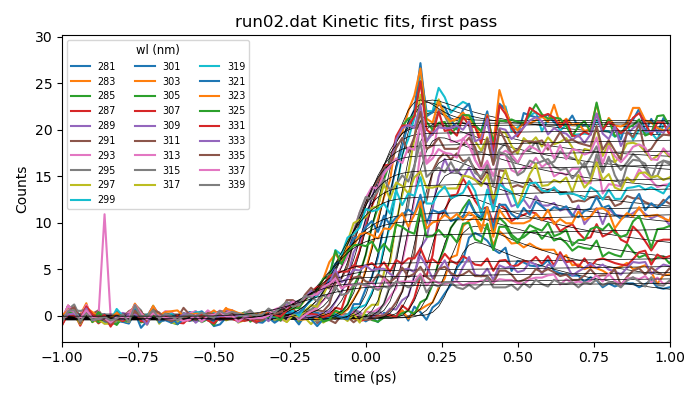

In [32]:
fig, axes = plt.subplots(
    nrows=len(data),
    figsize=(7, 4*len(data)),
    squeeze=False
)

axes = dict(zip(data, axes.flat))

all_wl = sorted(list(set([k[1] for k in bands.keys()])))

for (sample, cwl), res in results.items():

    t = data[sample][0]

    k = kins[sample, cwl]

    plt.sca(axes[sample])

    plt.plot(t, k, label=cwl)
    plt.plot(t, res.best_fit, color="k", lw=0.5)

for sample, ax in axes.items():

    ax.legend(ncols=3, fontsize="x-small",
              title="wl (nm)", title_fontsize="small")

    ax.set_title(f"{sample} Kinetic fits, first pass")
    ax.set_xlabel("time (ps)")
    ax.set_ylabel("Counts")
    ax.set_xlim(-1, 1)

plt.tight_layout()
plt.show()

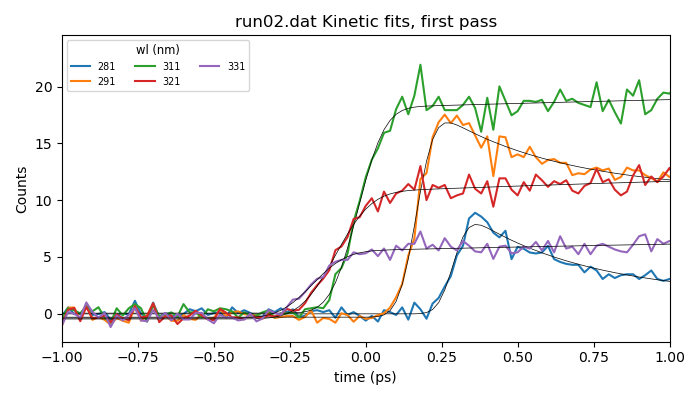

In [33]:
show_wl = [ 281, 291, 311, 321, 331, 343]

fig, axes = plt.subplots(
    nrows=len(data),
    figsize=(7, 4*len(data)),
    squeeze=False
)

axes = dict(zip(data, axes.flat))

for (sample, cwl), res in results.items():

    if cwl not in show_wl:
        continue

    t = data[sample][0]
    k = kins[sample, cwl]

    axes[sample].plot(t, k, label=cwl)
    axes[sample].plot(t, res.best_fit, color="k", lw=0.5)

for sample, ax in axes.items():

    ax.legend(
        ncols=3,
        fontsize="x-small",
        title="wl (nm)",
        title_fontsize="small"
    )

    ax.set_title(f"{sample} Kinetic fits, first pass")
    ax.set_xlabel("time (ps)")
    ax.set_ylabel("Counts")
    ax.set_xlim(-1, 1)

plt.tight_layout()
plt.show()

In [34]:
#r = results[('PBBO', 333)]
print(r.fit_report(show_correl=False))

[[Model]]
    (Model(conv_exp) + Model(constant))
[[Fit Statistics]]
    # fitting method   = leastsq
    # function evals   = 50
    # data points      = 251
    # variables        = 5
    chi-square         = 45.8662028
    reduced chi-square = 0.18644798
    Akaike info crit   = -416.630828
    Bayesian info crit = -399.003563
    R-squared          = 0.93001934
[[Variables]]
    amp:   -2.08955151 +/- 4.48275352 (214.53%) (init = 100)
    tau:    7.89441062 +/- 22.2395259 (281.71%) (init = 1)
    sigma:  0.12859443 +/- 0.02004083 (15.58%) (init = 0.1)
    t0:    -0.20356939 +/- 0.01539792 (7.56%) (init = 0)
    y0:     5.31120951 +/- 4.60018110 (86.61%) (init = 3.781818)
    c:     -0.0636368 (fixed)


In [35]:
# collect the parameters into a dataframe
t1_df = []
for (sample, cwl), r in results.items():
    if cwl == wl_cc:
        continue
    t1_df.append([sample, cwl, r.params["amp"].value, r.params["amp"].stderr, r.params["tau"].value, r.params["tau"].stderr,r.params["sigma"].value, r.params["sigma"].stderr])
t1_df = pd.DataFrame.from_records(
    t1_df,
    columns=("sample", "wl", "amp", "amp_err", "tau", "tau_err", "sigma", "sigma_err"))

In [36]:
print(t1_df)

       sample   wl         amp       amp_err         tau        tau_err  \
0   run02.dat  281    7.984635      0.249196    0.394153       0.019496   
1   run02.dat  283    8.994628      0.267641    0.429018       0.020382   
2   run02.dat  285    8.013577      0.525257    0.569836       0.069103   
3   run02.dat  287    8.649620      0.316183    0.477722       0.028491   
4   run02.dat  289    8.547644      0.374498    0.434234       0.029391   
5   run02.dat  291    8.172024      0.444127    0.403963       0.032302   
6   run02.dat  293    8.319258      0.518856    0.375319       0.033202   
7   run02.dat  295    7.818657      0.548802    0.390643       0.039226   
8   run02.dat  297    7.877022      0.817853    0.300959       0.039435   
9   run02.dat  299    6.502320      0.862296    0.315903       0.052065   
10  run02.dat  301    6.872197      2.906329    0.145181       0.055226   
11  run02.dat  303   69.732978    436.099379    0.020000       0.028294   
12  run02.dat  305 -113.4

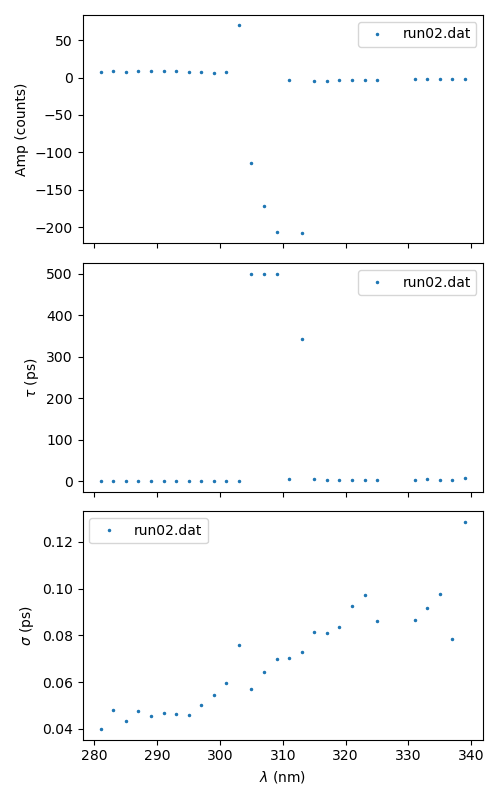

In [37]:
fig, axes = plt.subplots(nrows=3, figsize=(5,8), sharex=True)

for sample, group in t1_df.groupby(by="sample"):
    plt.sca(axes[0])
    plt.plot(group.wl, group.amp, ".", ms=3, label=sample)
    plt.sca(axes[1])
    plt.plot(group.wl, group.tau, ".", ms=3, label=sample)
    plt.sca(axes[2])
    plt.plot(group.wl, group.sigma, ".", ms=3, label=sample)
for ax in axes:
    ax.legend(loc="best")
#axes[0].set_ylim(-370, 30)
axes[0].set_ylabel("Amp (counts)")
#axes[1].set_ylim(-0.1, 1.5)
axes[1].set_ylabel(r"$\tau$ (ps)")
#axes[2].set_ylim(0, 0.16)
axes[2].set_ylabel(r"$\sigma$ (ps)")
axes[-1].set_xlabel(r"$\lambda$ (nm)")
plt.tight_layout()

In [38]:
# compute average tau
tau_avg = {}
for sample, group in t1_df.groupby(by="sample"):
    sel = group.query("wl>280")
    tau_avg[sample] = np.average(sel.tau, weights=1/sel.tau_err)
tau_avg

{'run02.dat': 0.39108997642784205}

In [39]:
# compute average tau
sigma_avg = {}
for sample, group in t1_df.groupby(by="sample"):
    sel = group.query("wl>280")
    sigma_avg[sample] = np.average(sel.sigma, weights=1/sel.sigma_err)
sigma_avg

{'run02.dat': 0.060229919460218995}

In [40]:
fwhm=0.06*2.35
print("fwhm signal:", fwhm)

fwhm signal: 0.141


# Collect time zero points obtained from fit

In [41]:
payload = [(sample, wl, r.params["t0"].value, r.params["t0"].stderr, r.params["sigma"].value,) for (sample, wl), r in results.items()]
#payload.extend([(sample, wl, r.params["center"].value, r.params["center"].stderr, r.params["sigma"].value,) for (sample, wl), r in results_cc.items()])
#payload.append([282, 0.280, 0.005, np.nan]) # manual determination of Raman line
timings = pd.DataFrame.from_records(
    payload,
    columns=("sample", "wl", "t0", "t0_err", "irfw")).sort_values(by="wl")
timings["wl_f"] = 1/(1/timings.wl - 1/1340)
timings
timings_org = timings.copy()

In [42]:
timings = timings_org.copy()
#timings.loc[timings["sample"] == "PBBO"] -= 0.02 # manually compensate for slight overlap


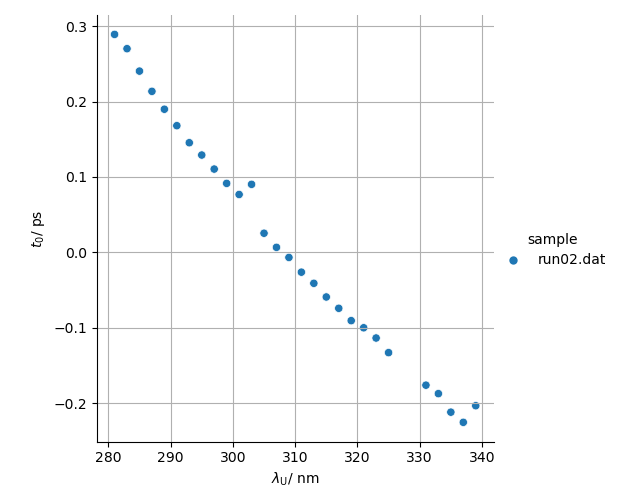

In [43]:
sns.relplot(data=timings, x="wl", y="t0", hue="sample")
#plt.ylim(-0.8,0.8)
#plt.xlim(305,375)
plt.ylabel("$t_0$/ ps")
plt.xlabel("$\lambda_\mathrm{U}$/ nm")
plt.grid()

# Second pass with fixing tau

In [37]:
model_sig = lmfit.Model(conv_exp) + lmfit.models.ConstantModel()
guesses = {}
guess = model_sig.make_params()
guess["amp"].set(value=1, vary=True)
guess["tau"].set(value=1.0, max=5, min=0.02, vary=True)
guess["sigma"].set(value=0.2, min=0.02)
guess["t0"].set(value=-1.0)
guess["y0"].set(value=0, vary=True, min=0, max= 5000)
guess["c"].set(value=0, vary=False, min=-100, max=100)

for sample in data:
    guesses[sample] = guess.copy()
    guesses[sample]["tau"].set(value=tau_avg[sample], vary=False)


results = {}
for b, k in kins.items():
    t = data[b[0]][0]
    if b[1] == wl_cc: continue
    g = guesses[b[0]]
    y_ = np.mean(k[-10:])
    g["y0"].set(value=y_)
    g["c"].set(value=np.mean(k[:10]))
    m = np.isfinite(k)
    r = model_sig.fit(k[m], params=g, x=t[m])
    print(f"{b} {r.message}")
    results[b] = r

('run01.dat', 282) Fit succeeded.
('run01.dat', 283) Fit succeeded.
('run01.dat', 284) Fit succeeded.
('run01.dat', 285) Fit succeeded.
('run01.dat', 286) Fit succeeded.
('run01.dat', 287) Fit succeeded.
('run01.dat', 288) Fit succeeded.
('run01.dat', 289) Fit succeeded.
('run01.dat', 290) Fit succeeded.
('run01.dat', 291) Fit succeeded.
('run01.dat', 292) Fit succeeded.
('run01.dat', 293) Fit succeeded.
('run01.dat', 294) Fit succeeded.
('run01.dat', 295) Fit succeeded.
('run01.dat', 296) Fit succeeded.
('run01.dat', 297) Fit succeeded.
('run01.dat', 298) Fit succeeded.
('run01.dat', 299) Fit succeeded.
('run01.dat', 300) Fit succeeded.
('run01.dat', 301) Fit succeeded.
('run01.dat', 302) Fit succeeded.
('run01.dat', 303) Fit succeeded.
('run01.dat', 304) Fit succeeded.
('run01.dat', 305) Fit succeeded.
('run01.dat', 306) Fit succeeded.
('run01.dat', 307) Fit succeeded.
('run01.dat', 308) Fit succeeded.
('run01.dat', 309) Fit succeeded.
('run01.dat', 310) Fit succeeded.
('run01.dat', 

TypeError: 'Axes' object is not iterable

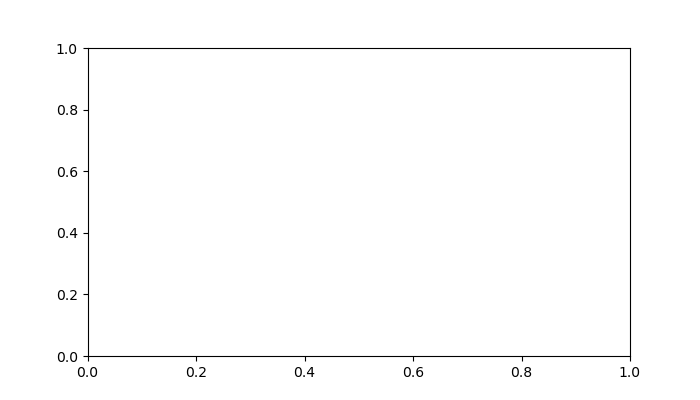

In [38]:
fig, axes = plt.subplots(nrows=len(data), figsize=(7, 4*len(data)))
axes = dict(zip(data, axes))
all_wl = sorted(list(set([k[1] for k in bands.keys()])))
#colors = plt.get_cmap("Blues")(np.linspace(0, 1, len(all_wl)))
#colors = dict(zip(all_wl, colors))
for (sample, cwl), res in results.items():
    t = data[sample][0]
    k = kins[sample, cwl]
    plt.sca(axes[sample])
    plt.plot(t, k, label=cwl)
    plt.plot(t, res.best_fit, color="k", lw=0.5)
for sample, ax in axes.items():
    t = data[sample][0]
    ax.legend(ncols=3, fontsize="x-small", title="wl (nm)", title_fontsize="small")
    ax.set_title(f"{sample} Kinetic fits, second pass")
    ax.set_xlabel("time (ps)")
    ax.set_ylabel("Counts")

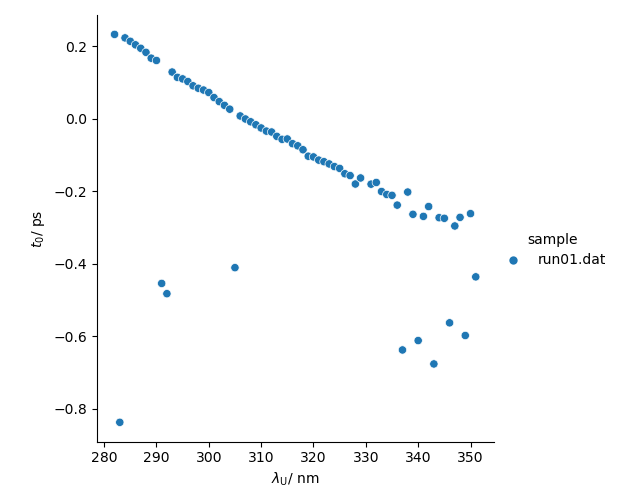

In [39]:
payload = [(sample, wl, r.params["t0"].value, r.params["t0"].stderr, r.params["sigma"].value,) for (sample, wl), r in results.items()]
#payload.extend([(sample, wl, r.params["center"].value, r.params["center"].stderr, r.params["sigma"].value,) for (sample, wl), r in results_cc.items()])
#payload.append([282, 0.280, 0.005, np.nan]) # manual determination of Raman line
timings = pd.DataFrame.from_records(
    payload,
    columns=("sample", "wl", "t0", "t0_err", "irfw")).sort_values(by="wl")
timings["wl_f"] = 1/(1/timings.wl - 1/1340)
timings
timings_org = timings.copy()

timings = timings_org.copy()
timings.loc[timings["sample"] == "eun03.dat", "t0"] -= 0.02 # manually compensate for slight overlap

sns.relplot(data=timings, x="wl", y="t0", hue="sample")
#plt.xlim(300,370)
#plt.ylim(-1, 1)
#plt.ylim(-2, -0.26)
plt.ylabel("$t_0$/ ps")
plt.xlabel("$\lambda_\mathrm{U}$/ nm")
plt.show()

# Fit t0 curve with Polynomial

In [47]:
timings_PBBO = timings[timings["sample"] == "run02.dat"].sort_values("wl").iloc[0:].copy()

In [48]:
# polynomial fit weighed with inverse error

polys = {}
for order in [1,2,3,4]:
    polys[order] = np.polyfit(nm2eV(timings_PBBO.wl), timings_PBBO.t0, w=1/timings_PBBO.t0_err, deg=order)
t0_curves = {order: np.polyval(p, nm2eV(wl)) for order, p in polys.items()}

In [49]:
print("order, b_i")
polys

order, b_i


{1: array([ 0.70978984, -2.85168058]),
 2: array([ 0.17239435, -0.70878353,  0.06084064]),
 3: array([ 0.07808876, -0.78520044,  3.19953647, -5.24795993]),
 4: array([   0.56054444,   -9.05637848,   54.96458466, -147.83205293,
         147.98874275])}

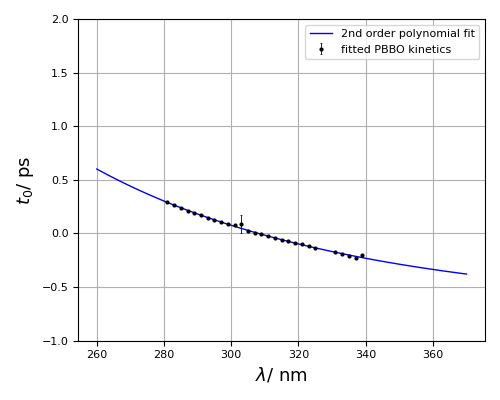

In [51]:
plt.figure(figsize=(5,4),dpi=100)
plt.errorbar(timings_PBBO.wl, timings_PBBO.t0, yerr=timings_PBBO.t0_err,
             fmt='o', ms=2, capsize=0.5, capthick=0.5, elinewidth=0.6, color='k', label="fitted PBBO kinetics")
wl_fit = np.linspace(260,400, 500)
x_fit = nm2eV(wl_fit)
#for order, coeffs in polys.items():
#    plt.plot(wl_fit, np.polyval(coeffs, x_fit), lw=1, label=f'poly deg {order}')
plt.plot(wl_fit, np.polyval(polys[2], x_fit), lw=1, color='b', label='2nd order polynomial fit')
#plt.xlim(300,370)
plt.ylim(-1, 2)
plt.xlabel(r"$\lambda$/ nm", fontsize=13)
plt.ylabel(r"$t_0$/ ps", fontsize=13)
plt.xticks(fontsize=8)
plt.yticks(fontsize=8)
plt.legend(fontsize=8)
plt.grid()
plt.tight_layout()
#plt.savefig('261006_FLUPS_run01_t0-corr_2nd-poly.png', dpi=500)
plt.show()

In [52]:
chi2_red = {}
for order, coeffs in polys.items():
    y_fit = np.polyval(coeffs, nm2eV(timings_PBBO.wl))
    resid = timings_PBBO.t0 - y_fit
    chi2 = np.sum((resid / timings_PBBO.t0_err)**2)
    dof = len(timings_PBBO) - (order + 1)  
    chi2_red[order] = chi2 / dof

print("Reduced chi-squared per order:")
for order, val in chi2_red.items():
    print(f"{order}: {val:.3f}")

Reduced chi-squared per order:
1: 3.327
2: 0.989
3: 1.005
4: 1.008


In [54]:
wl_fit = np.linspace(240,450, 500)
x_fit = nm2eV(wl_fit)

#np.savetxt('261006_FLUPS_t0-corr_run01.txt', np.vstack(polys[2]))

In [ ]:
#save parameters instead, look at TA